<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/clahe_gercekleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files
yuklenen = files.upload()
dosya_adi = list(yuklenen.keys())[0]
print("Yüklenen dosya:", dosya_adi)

Saving image5.jpeg to image5.jpeg
Yüklenen dosya: image5.jpeg


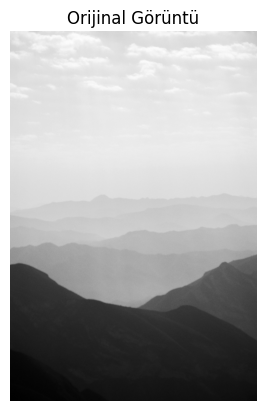

In [ ]:
resim = cv2.imread("image5.jpeg", cv2.IMREAD_GRAYSCALE)

plt.imshow(resim, cmap='gray')
plt.title("Orijinal Görüntü")
plt.axis('off')
plt.show()

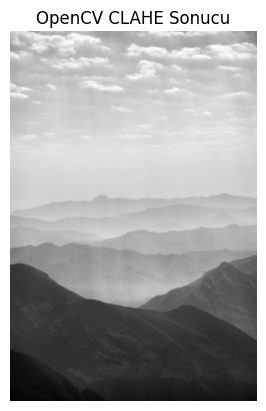

In [ ]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

clahe_resim = clahe.apply(resim)

plt.imshow(clahe_resim, cmap='gray')
plt.title("OpenCV CLAHE Sonucu")
plt.axis('off')
plt.show()

In [ ]:
yukseklik, genislik = resim.shape

bolge_sayisi = 8
clip_limit = 2.0

bolge_yukseklik = yukseklik // bolge_sayisi
bolge_genislik = genislik // bolge_sayisi

yeni_resim = np.zeros((yukseklik, genislik), dtype=np.uint8)

for a in range(bolge_sayisi):
    for b in range(bolge_sayisi):

        y1 = a * bolge_yukseklik
        y2 = (a + 1) * bolge_yukseklik

        x1 = b * bolge_genislik
        x2 = (b + 1) * bolge_genislik

        bolge = resim[y1:y2, x1:x2]

        histogram = [0] * 256

        for i in range(bolge.shape[0]):
            for j in range(bolge.shape[1]):
                histogram[bolge[i, j]] += 1

        toplam = bolge.size
        limit = int(clip_limit * toplam / 256)

        tasan = 0

        for i in range(256):
            if histogram[i] > limit:
                tasan += histogram[i] - limit
                histogram[i] = limit

        for i in range(256):
            histogram[i] += tasan // 256

        for i in range(tasan % 256):
            histogram[i] += 1

        cdf = [0] * 256
        cdf[0] = histogram[0]

        for i in range(1, 256):
            cdf[i] = cdf[i-1] + histogram[i]

        cdf_min = 0

        for i in range(256):
            if cdf[i] > 0:
                cdf_min = cdf[i]
                break

        yeni_deger = [0] * 256

        for i in range(256):
            if toplam > cdf_min:
                deger = ((cdf[i] - cdf_min) / (toplam - cdf_min)) * 255
                yeni_deger[i] = max(0, min(255, int(deger)))

        for i in range(bolge.shape[0]):
            for j in range(bolge.shape[1]):
                yeni_resim[y1+i, x1+j] = yeni_deger[bolge[i, j]]

print("Manuel CLAHE işlemi tamamlandı.")

Manuel CLAHE işlemi tamamlandı.


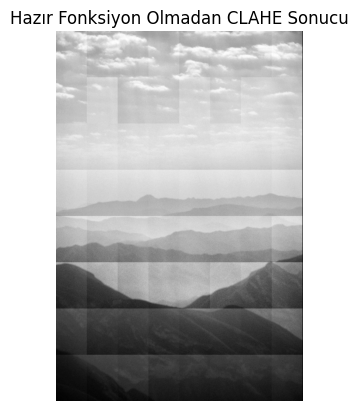

In [ ]:
plt.imshow(yeni_resim, cmap='gray')
plt.title("Hazır Fonksiyon Olmadan CLAHE Sonucu")
plt.axis('off')
plt.show()

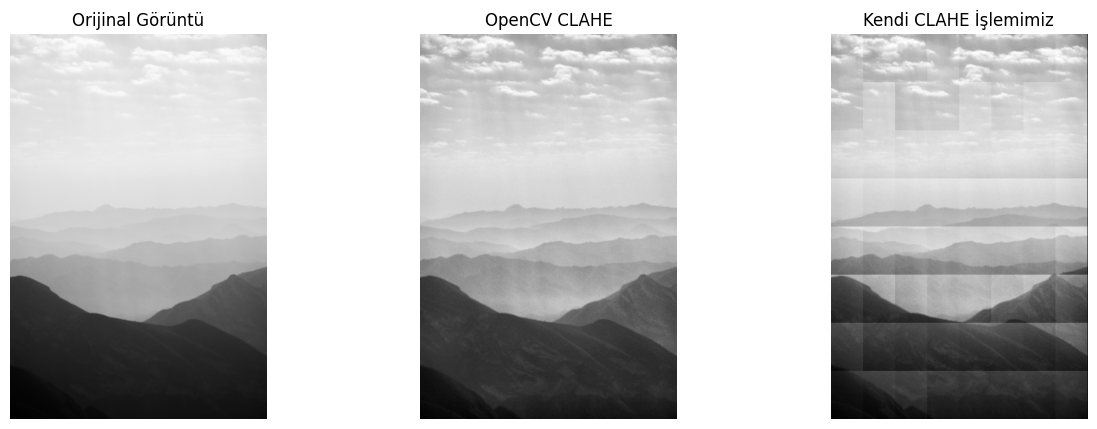

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(resim, cmap='gray')
plt.title("Orijinal Görüntü")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(clahe_resim, cmap='gray')
plt.title("OpenCV CLAHE")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(yeni_resim, cmap='gray')
plt.title("Kendi CLAHE İşlemimiz")
plt.axis('off')

plt.show()